# Titanic Dataset — Exploratory Data Analysis (EDA)
**Elevvo Internship | Task 2 — Level 1**

This notebook explores the Titanic passenger dataset, cleans missing and duplicate data, checks data types, calculates summary statistics, investigates survival patterns by gender and passenger class, and visualizes relationships and correlations.

> **Dataset loading:** The notebook downloads the CSV directly from a public GitHub raw URL. You do not need to upload a local dataset file.

## Objectives
1. Load and inspect the dataset.
2. Understand columns, data types, missing values, and duplicates.
3. Clean the data using appropriate strategies.
4. Generate summary statistics and group-based insights.
5. Visualize survival rates by gender, class, and embarkation port.
6. Explore numerical correlations and summarize key findings.


## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


## 2. Load the dataset online

The dataset is the commonly used Titanic training dataset (891 passenger records). If the first source is unavailable, the second public source is tried automatically.

In [2]:
dataset_urls = [
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv",
    "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
]

df = None
last_error = None

for url in dataset_urls:
    try:
        df = pd.read_csv(url)
        print(f"Dataset loaded successfully from: {url}")
        break
    except Exception as error:
        last_error = error
        print(f"Could not load from {url}")

if df is None:
    raise RuntimeError(
        "The dataset could not be downloaded. Check your internet connection and run this cell again."
    ) from last_error

# Standardize column names so the remaining analysis works with either source.
df.columns = [col.strip().replace(" ", "_") for col in df.columns]

# The fallback seaborn dataset uses lowercase column names and has no PassengerId.
if "survived" in df.columns and "Survived" not in df.columns:
    df = df.rename(columns={
        "survived": "Survived", "pclass": "Pclass", "sex": "Sex",
        "age": "Age", "sibsp": "SibSp", "parch": "Parch",
        "fare": "Fare", "embarked": "Embarked"
    })

print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully from: https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,NaN,S


## 3. Initial data inspection

In [3]:
print("Dataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe(include="all").T)

print("\nMissing values:")
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Percentage", ascending=False)
display(missing_summary)

print("\nDuplicate rows:", df.duplicated().sum())


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.00,NaN,NaN,NaN,446.00,257.35,1.00,223.50,446.00,668.50,891.00
Survived,891.00,NaN,NaN,NaN,0.38,0.49,0.00,0.00,0.00,1.00,1.00
Pclass,891.00,NaN,NaN,NaN,2.31,0.84,1.00,2.00,3.00,3.00,3.00
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.00,NaN,NaN,NaN,29.70,14.53,0.42,20.12,28.00,38.00,80.00
SibSp,891.00,NaN,NaN,NaN,0.52,1.10,0.00,0.00,0.00,1.00,8.00
Parch,891.00,NaN,NaN,NaN,0.38,0.81,0.00,0.00,0.00,0.00,6.00
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.00,NaN,NaN,NaN,32.20,49.69,0.00,7.91,14.45,31.00,512.33



Missing values:


,Missing Count,Missing Percentage
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00



Duplicate rows: 0


## 4. Data cleaning

Cleaning decisions:
- Remove exact duplicate rows.
- Fill missing `Age` values with the median because age is numeric and can be skewed.
- Fill missing `Embarked` values with the mode (most frequent category).
- Drop `Cabin` because it has a very high proportion of missing values in this dataset.
- Keep rows with missing `Survived` out of the analysis because the target outcome is required.
- Convert relevant columns to appropriate data types.

The original data is preserved in `df_raw`; cleaning is performed on a copy.

In [4]:
df_raw = df.copy()
df_clean = df.copy()

# Remove exact duplicate records.
df_clean = df_clean.drop_duplicates().copy()

# Drop Cabin when it exists and is mostly missing.
if "Cabin" in df_clean.columns and df_clean["Cabin"].isna().mean() > 0.40:
    df_clean = df_clean.drop(columns=["Cabin"])

# Fill missing numeric and categorical values.
if "Age" in df_clean.columns:
    df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

if "Embarked" in df_clean.columns:
    embarked_mode = df_clean["Embarked"].mode(dropna=True)
    if not embarked_mode.empty:
        df_clean["Embarked"] = df_clean["Embarked"].fillna(embarked_mode.iloc[0])

# The outcome must be known for survival analysis.
if "Survived" in df_clean.columns:
    df_clean = df_clean.dropna(subset=["Survived"])
    df_clean["Survived"] = df_clean["Survived"].astype("int64")

# Convert categorical columns to category dtype when present.
for col in ["Sex", "Embarked", "Pclass"]:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype("category")

print("Original shape:", df_raw.shape)
print("Cleaned shape:", df_clean.shape)
print("\nMissing values after cleaning:")
display(df_clean.isna().sum().to_frame("Missing Count"))


Original shape: (891, 12)
Cleaned shape: (891, 11)

Missing values after cleaning:


,Missing Count
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## 5. Feature engineering

In [5]:
# Create useful features for passenger-level analysis.
if {"SibSp", "Parch"}.issubset(df_clean.columns):
    df_clean["FamilySize"] = (
        df_clean["SibSp"].astype(int) + df_clean["Parch"].astype(int) + 1
    )
    df_clean["IsAlone"] = (df_clean["FamilySize"] == 1).astype(int)

if "Age" in df_clean.columns:
    df_clean["AgeGroup"] = pd.cut(
        df_clean["Age"],
        bins=[0, 12, 18, 35, 60, np.inf],
        labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"],
        include_lowest=True
    )

display(df_clean.head())


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,FamilySize,IsAlone,AgeGroup
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,S,2,0,Young Adult
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,71.28,C,2,0,Adult
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.92,S,1,1,Young Adult
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,S,2,0,Young Adult
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,S,1,1,Young Adult


## 6. Overall survival statistics

,Passenger Outcome,Count,Percentage
0,Did not survive,549,61.62
1,Survived,342,38.38


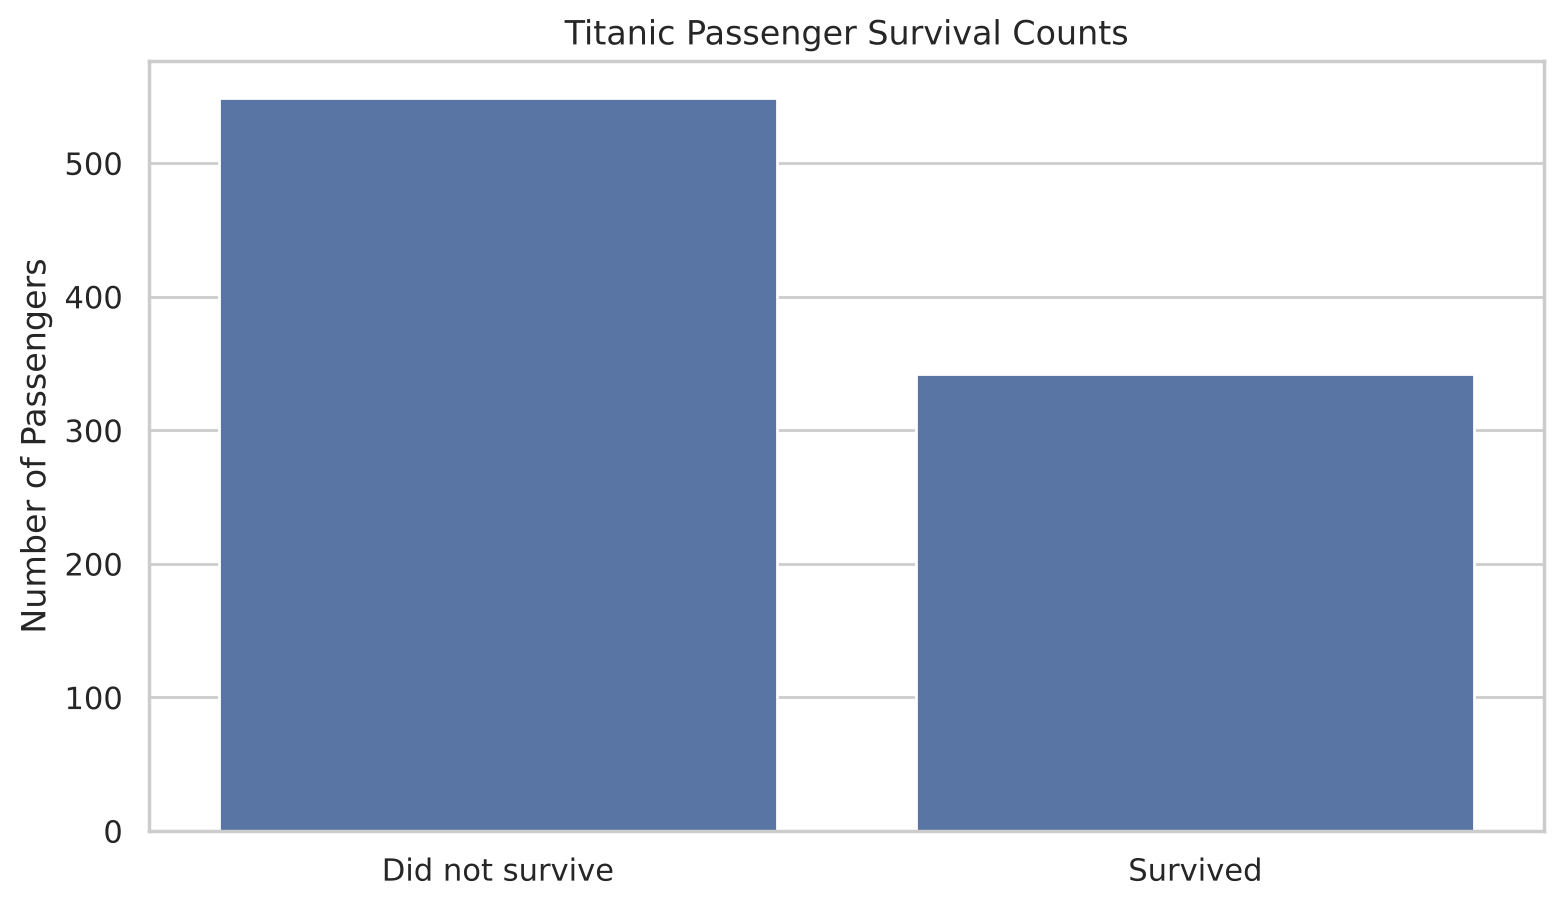

In [6]:
survival_counts = df_clean["Survived"].value_counts().sort_index()
survival_percentages = df_clean["Survived"].value_counts(normalize=True).sort_index() * 100

survival_summary = pd.DataFrame({
    "Passenger Outcome": ["Did not survive", "Survived"],
    "Count": [survival_counts.get(0, 0), survival_counts.get(1, 0)],
    "Percentage": [survival_percentages.get(0, 0), survival_percentages.get(1, 0)]
})
display(survival_summary.round(2))

ax = sns.barplot(data=survival_summary, x="Passenger Outcome", y="Count")
ax.set_title("Titanic Passenger Survival Counts")
ax.set_xlabel("")
ax.set_ylabel("Number of Passengers")
plt.show()


## 7. Survival by gender

,Sex,Passengers,Survival_Rate
0,female,314,74.20
1,male,577,18.89


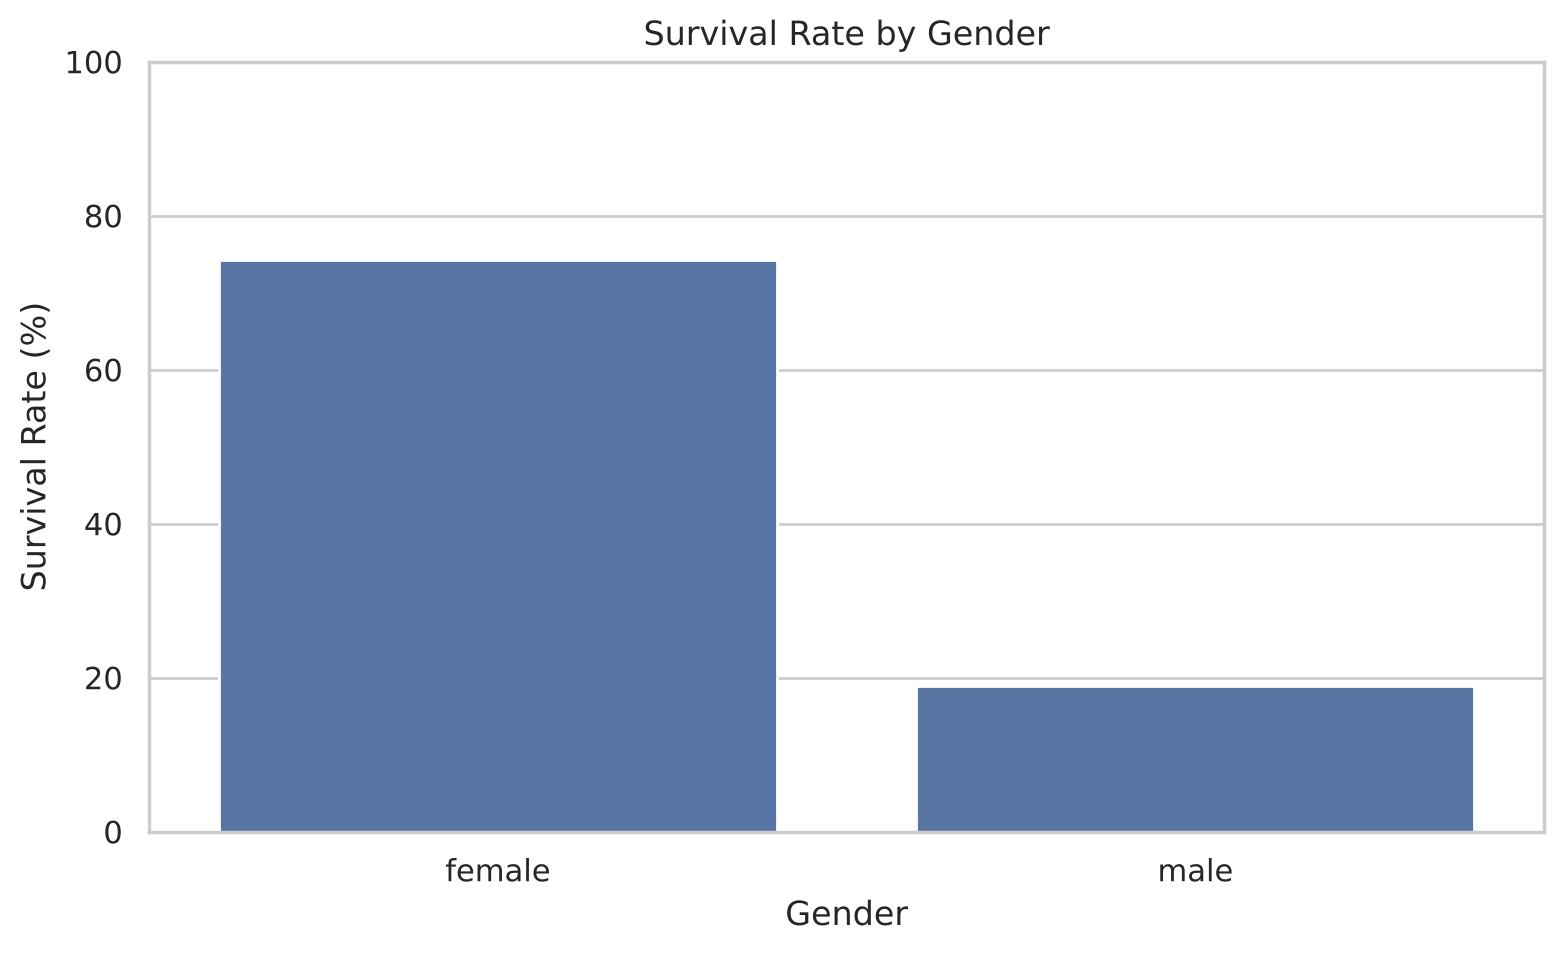

In [7]:
gender_survival = (
    df_clean.groupby("Sex", observed=False)["Survived"]
    .agg(Passengers="count", Survival_Rate="mean")
    .reset_index()
)
gender_survival["Survival_Rate"] *= 100
display(gender_survival.round(2))

sns.barplot(data=gender_survival, x="Sex", y="Survival_Rate")
plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.show()


## 8. Survival by passenger class

,Pclass,Passengers,Survival_Rate
0,1,216,62.96
1,2,184,47.28
2,3,491,24.24


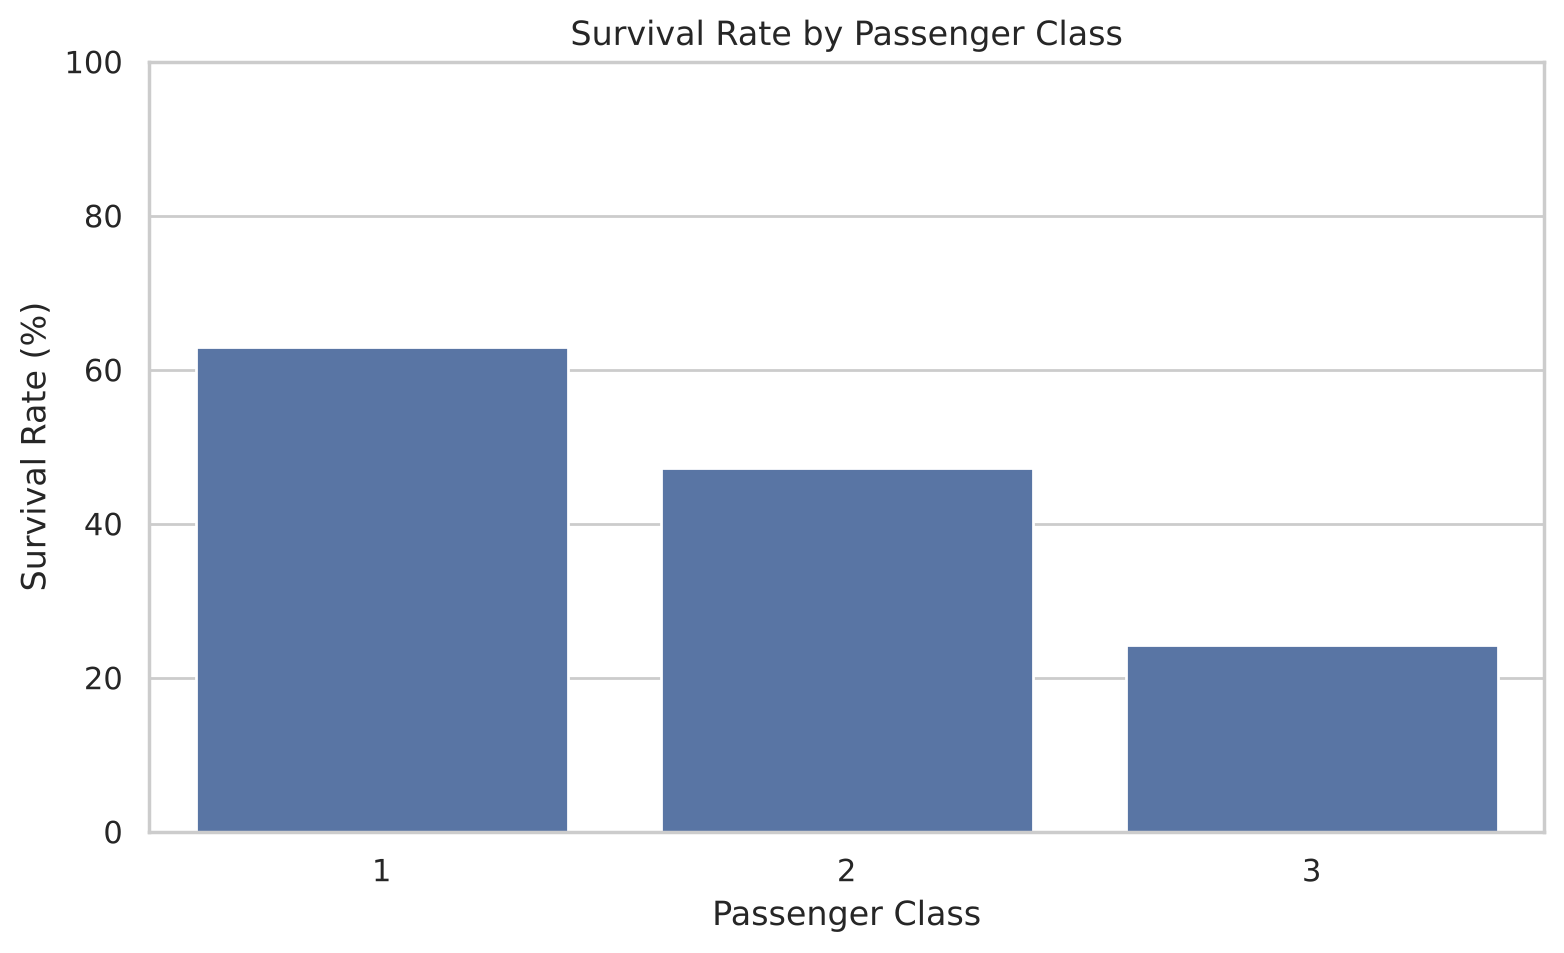

In [8]:
class_survival = (
    df_clean.groupby("Pclass", observed=False)["Survived"]
    .agg(Passengers="count", Survival_Rate="mean")
    .reset_index()
)
class_survival["Survival_Rate"] *= 100
display(class_survival.round(2))

sns.barplot(data=class_survival, x="Pclass", y="Survival_Rate")
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.show()


## 9. Survival by gender and passenger class

,Pclass,Sex,Survival_Rate
0,1,female,96.81
1,1,male,36.89
2,2,female,92.11
3,2,male,15.74
4,3,female,50.00
5,3,male,13.54


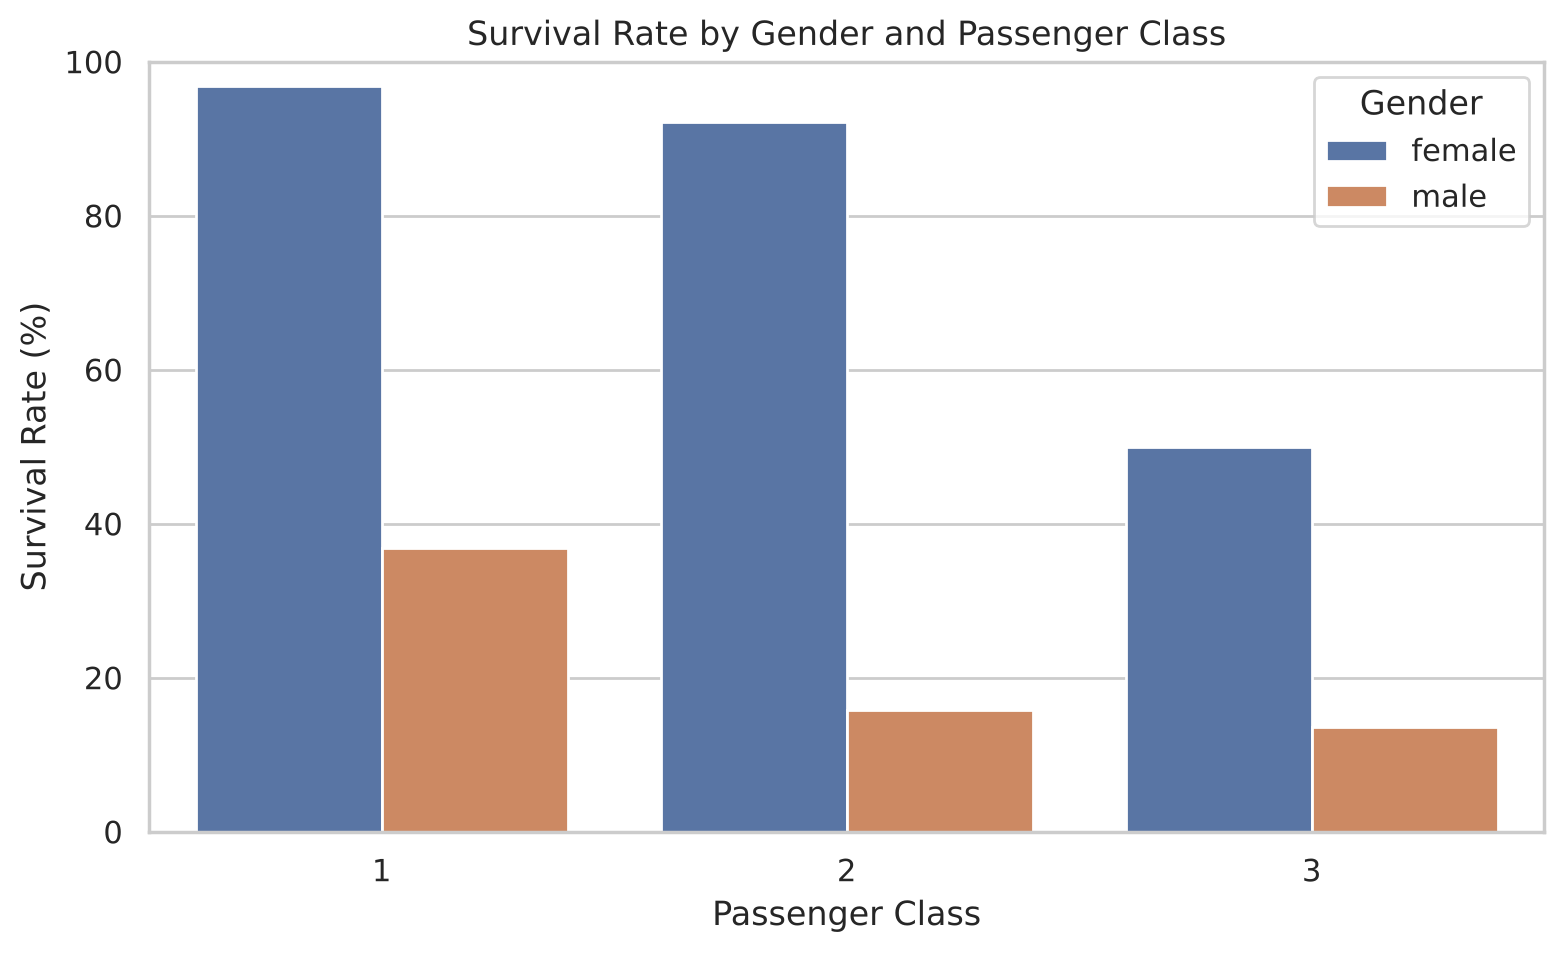

In [9]:
gender_class_survival = (
    df_clean.groupby(["Pclass", "Sex"], observed=False)["Survived"]
    .mean()
    .mul(100)
    .reset_index(name="Survival_Rate")
)
display(gender_class_survival.round(2))

sns.barplot(
    data=gender_class_survival,
    x="Pclass",
    y="Survival_Rate",
    hue="Sex"
)
plt.title("Survival Rate by Gender and Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.legend(title="Gender")
plt.show()


## 10. Survival by embarkation port

,Embarked,Passengers,Survival_Rate
0,C,168,55.36
1,Q,77,38.96
2,S,646,33.90


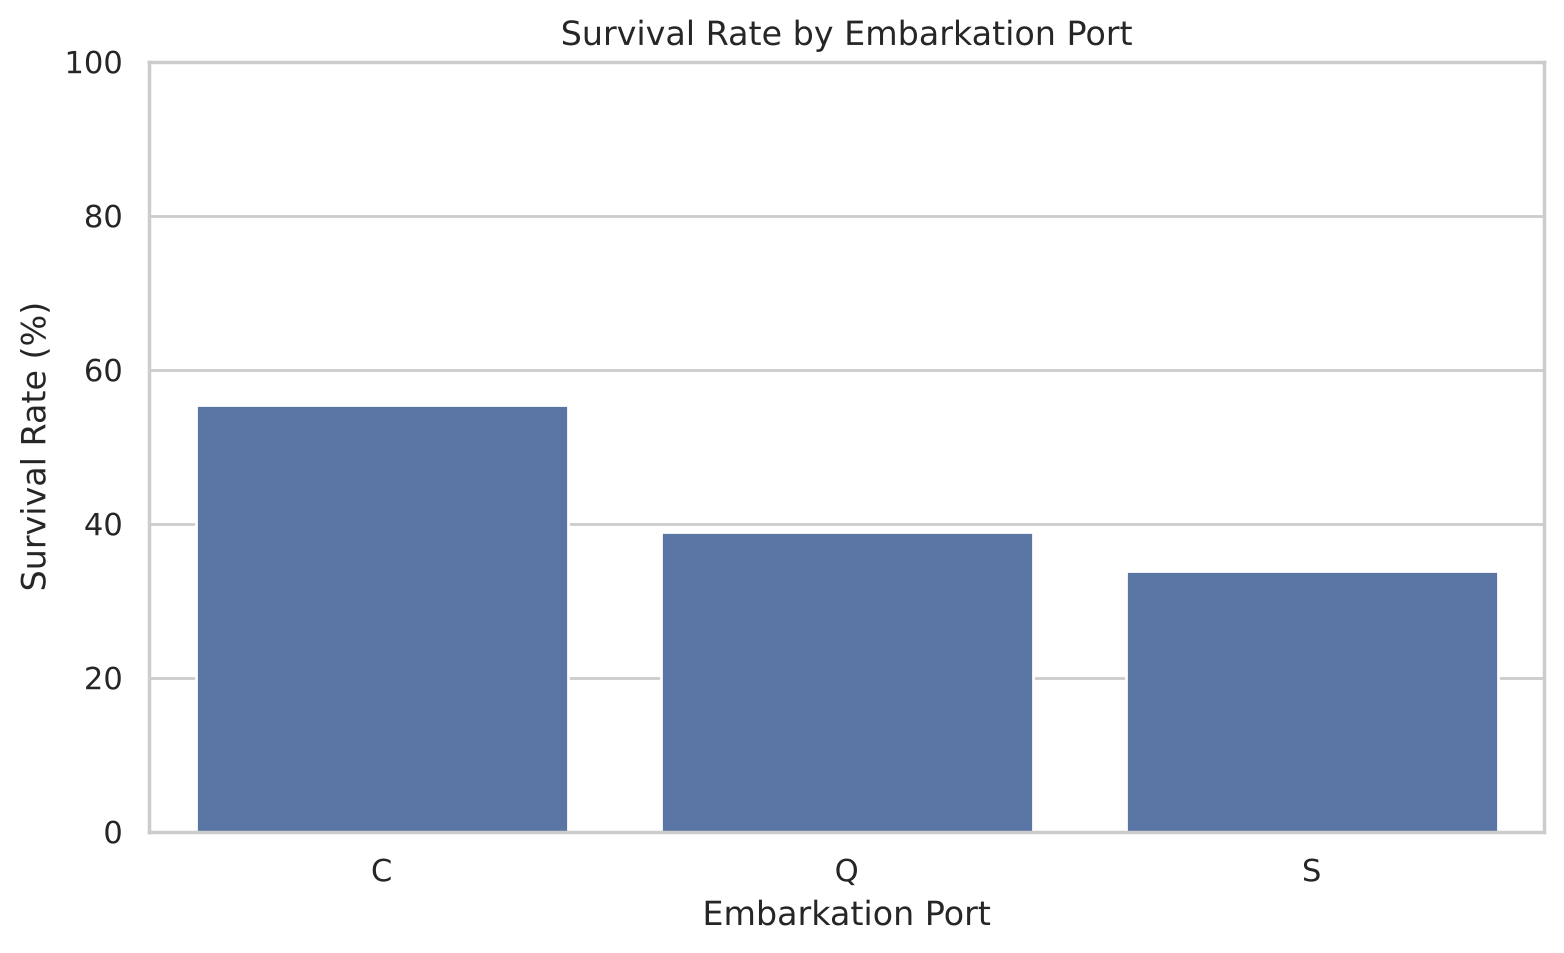

In [10]:
if "Embarked" in df_clean.columns:
    embarked_survival = (
        df_clean.groupby("Embarked", observed=False)["Survived"]
        .agg(Passengers="count", Survival_Rate="mean")
        .reset_index()
    )
    embarked_survival["Survival_Rate"] *= 100
    display(embarked_survival.round(2))

    sns.barplot(data=embarked_survival, x="Embarked", y="Survival_Rate")
    plt.title("Survival Rate by Embarkation Port")
    plt.xlabel("Embarkation Port")
    plt.ylabel("Survival Rate (%)")
    plt.ylim(0, 100)
    plt.show()
else:
    print("Embarked column is not available in this dataset.")


## 11. Age distribution and survival

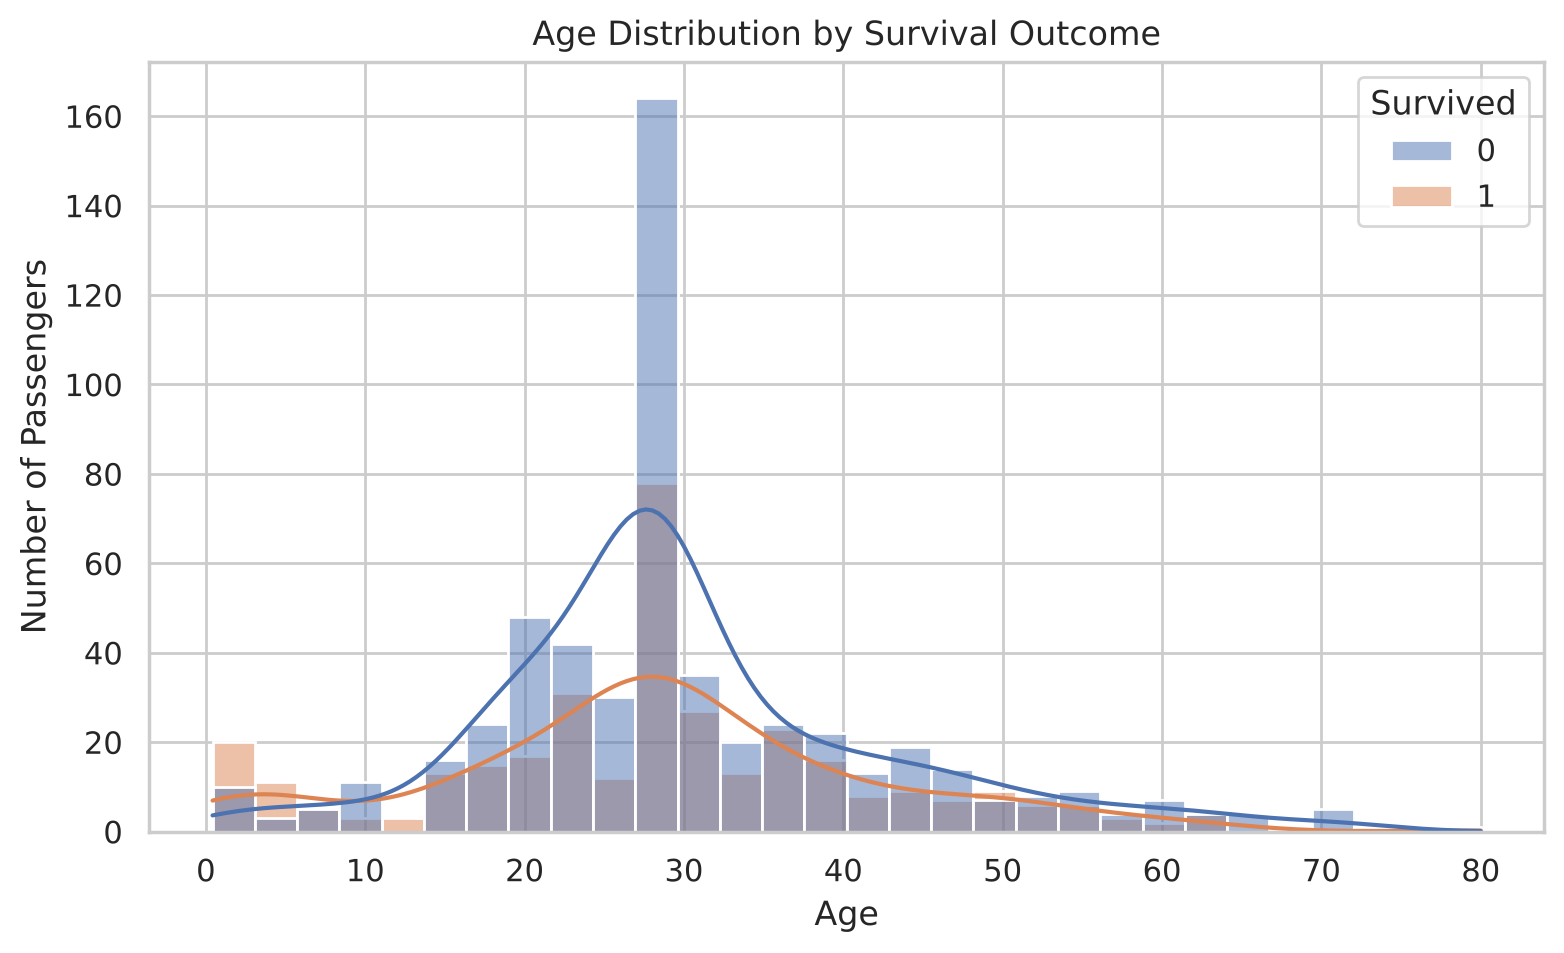

,AgeGroup,Survival_Rate
0,Child,57.97
1,Teenager,42.86
2,Young Adult,35.33
3,Adult,40.00
4,Senior,22.73


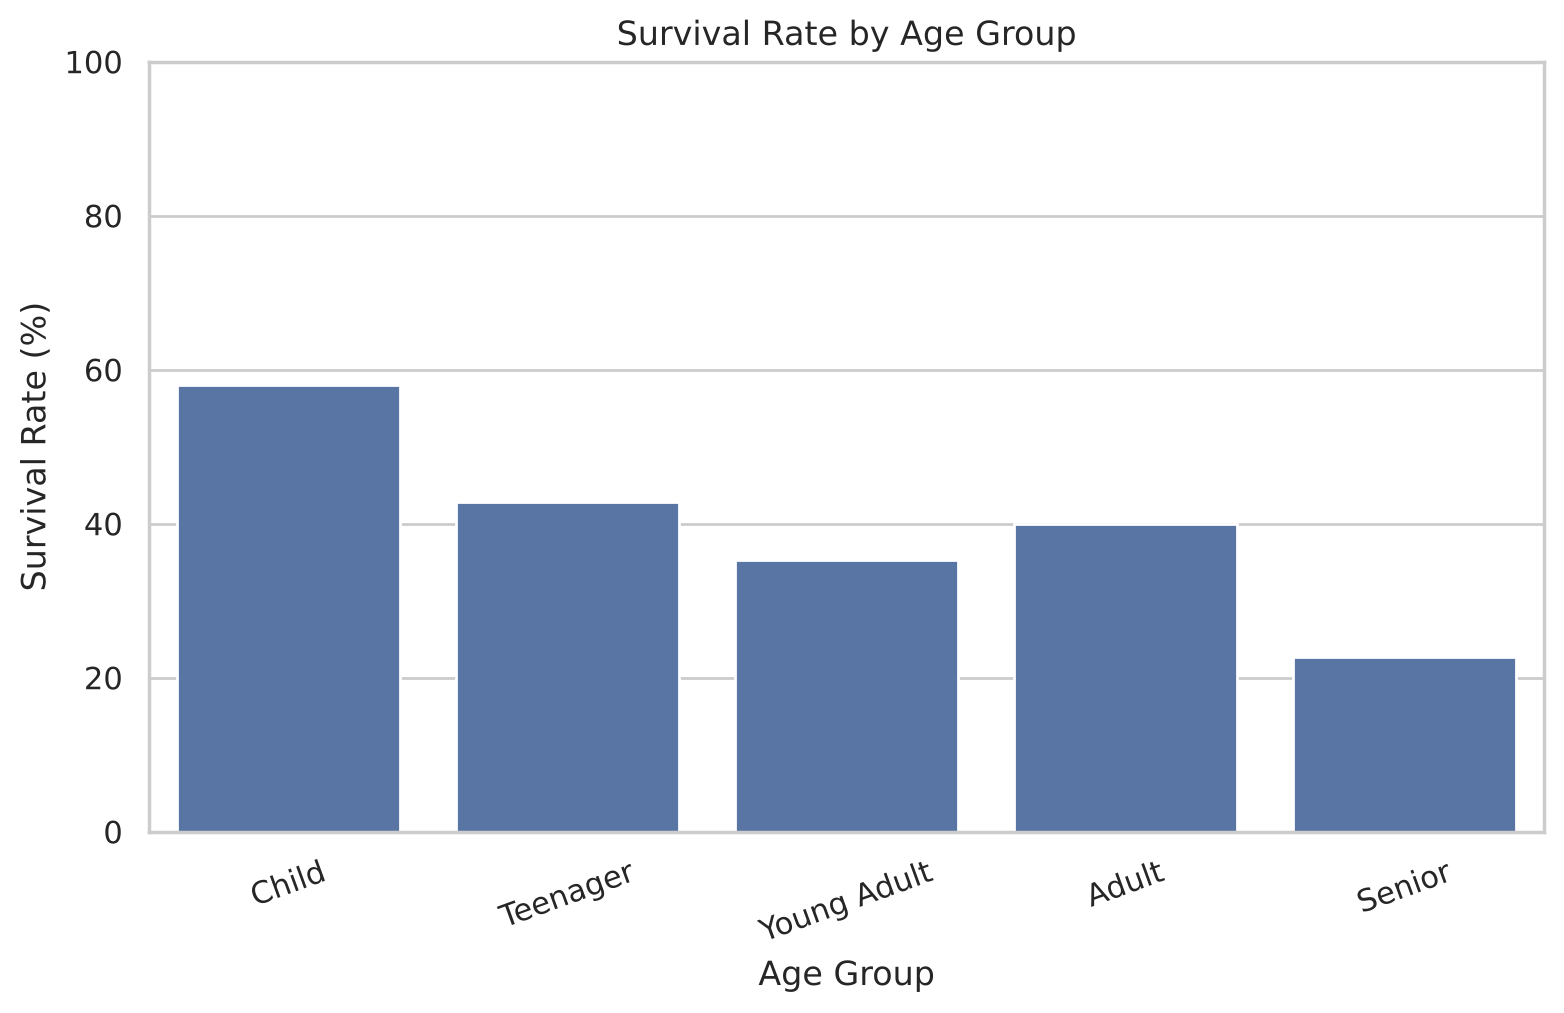

In [11]:
sns.histplot(data=df_clean, x="Age", hue="Survived", bins=30, kde=True, multiple="layer")
plt.title("Age Distribution by Survival Outcome")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

if "AgeGroup" in df_clean.columns:
    age_group_survival = (
        df_clean.groupby("AgeGroup", observed=False)["Survived"]
        .mean().mul(100).reset_index(name="Survival_Rate")
    )
    display(age_group_survival.round(2))

    sns.barplot(data=age_group_survival, x="AgeGroup", y="Survival_Rate")
    plt.title("Survival Rate by Age Group")
    plt.xlabel("Age Group")
    plt.ylabel("Survival Rate (%)")
    plt.xticks(rotation=20)
    plt.ylim(0, 100)
    plt.show()


## 12. Family size and survival

,FamilySize,Passengers,Survival_Rate
0,1,537,30.35
1,2,161,55.28
2,3,102,57.84
3,4,29,72.41
4,5,15,20.00
5,6,22,13.64
6,7,12,33.33
7,8,6,0.00
8,11,7,0.00


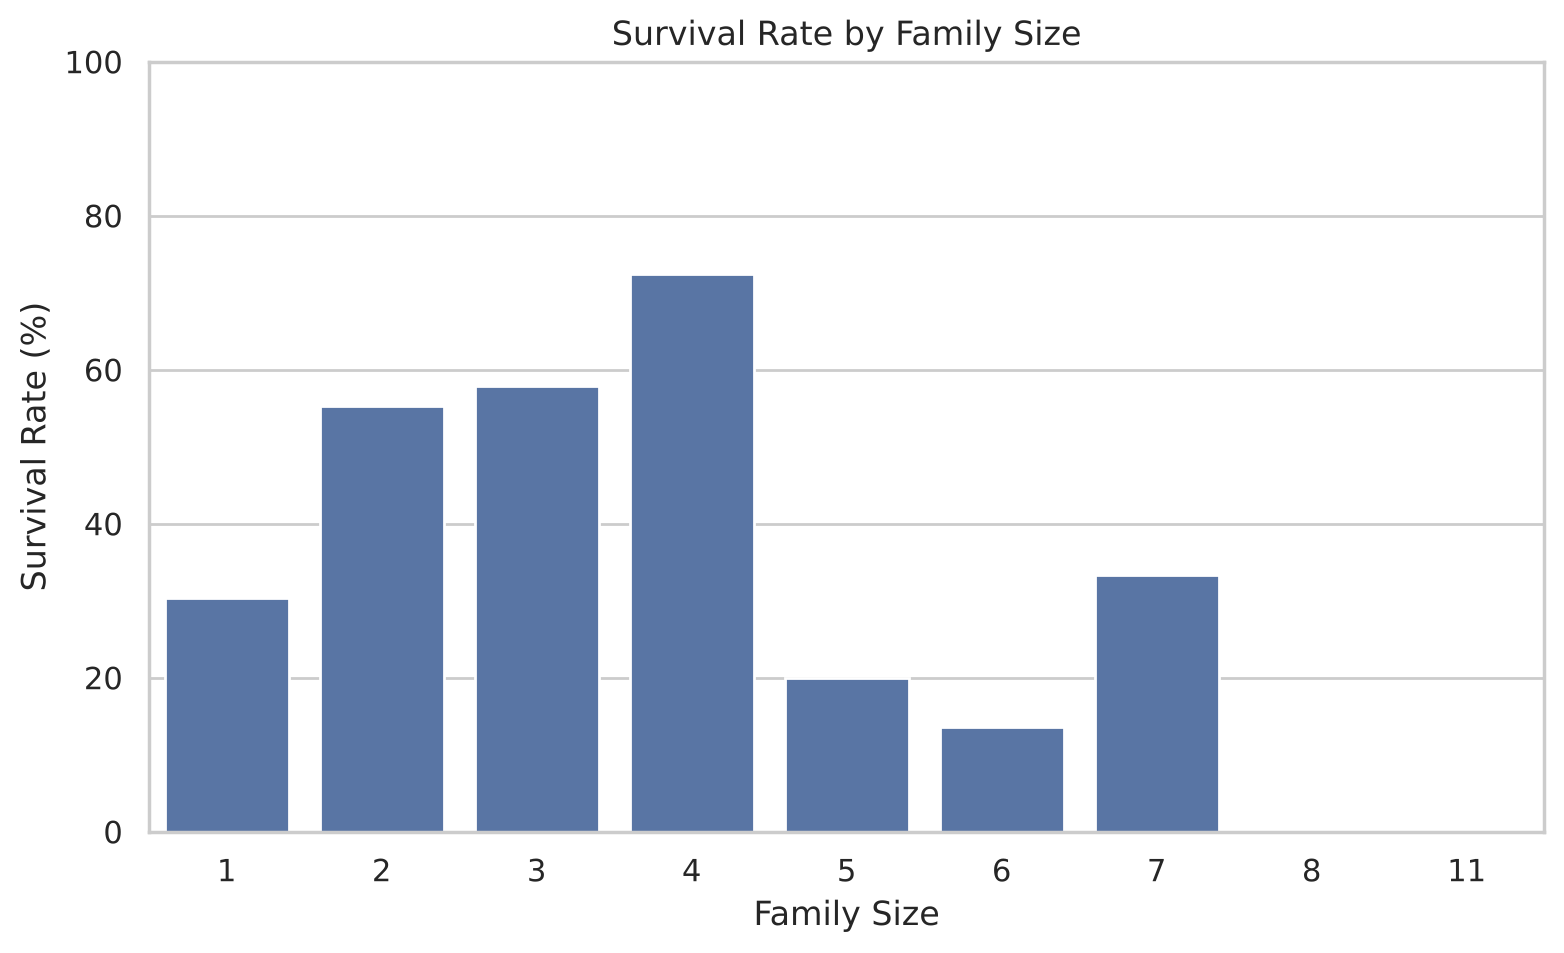

In [12]:
if "FamilySize" in df_clean.columns:
    family_survival = (
        df_clean.groupby("FamilySize")["Survived"]
        .agg(Passengers="count", Survival_Rate="mean")
        .reset_index()
    )
    family_survival["Survival_Rate"] *= 100
    display(family_survival.round(2))

    sns.barplot(data=family_survival, x="FamilySize", y="Survival_Rate")
    plt.title("Survival Rate by Family Size")
    plt.xlabel("Family Size")
    plt.ylabel("Survival Rate (%)")
    plt.ylim(0, 100)
    plt.show()


## 13. Correlation analysis and heatmap

,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone
Survived,1.00,-0.34,-0.06,-0.04,0.08,0.26,0.02,-0.20
Pclass,-0.34,1.00,-0.34,0.08,0.02,-0.55,0.07,0.14
Age,-0.06,-0.34,1.00,-0.23,-0.17,0.10,-0.25,0.17
SibSp,-0.04,0.08,-0.23,1.00,0.41,0.16,0.89,-0.58
Parch,0.08,0.02,-0.17,0.41,1.00,0.22,0.78,-0.58
Fare,0.26,-0.55,0.10,0.16,0.22,1.00,0.22,-0.27
FamilySize,0.02,0.07,-0.25,0.89,0.78,0.22,1.00,-0.69
IsAlone,-0.20,0.14,0.17,-0.58,-0.58,-0.27,-0.69,1.00


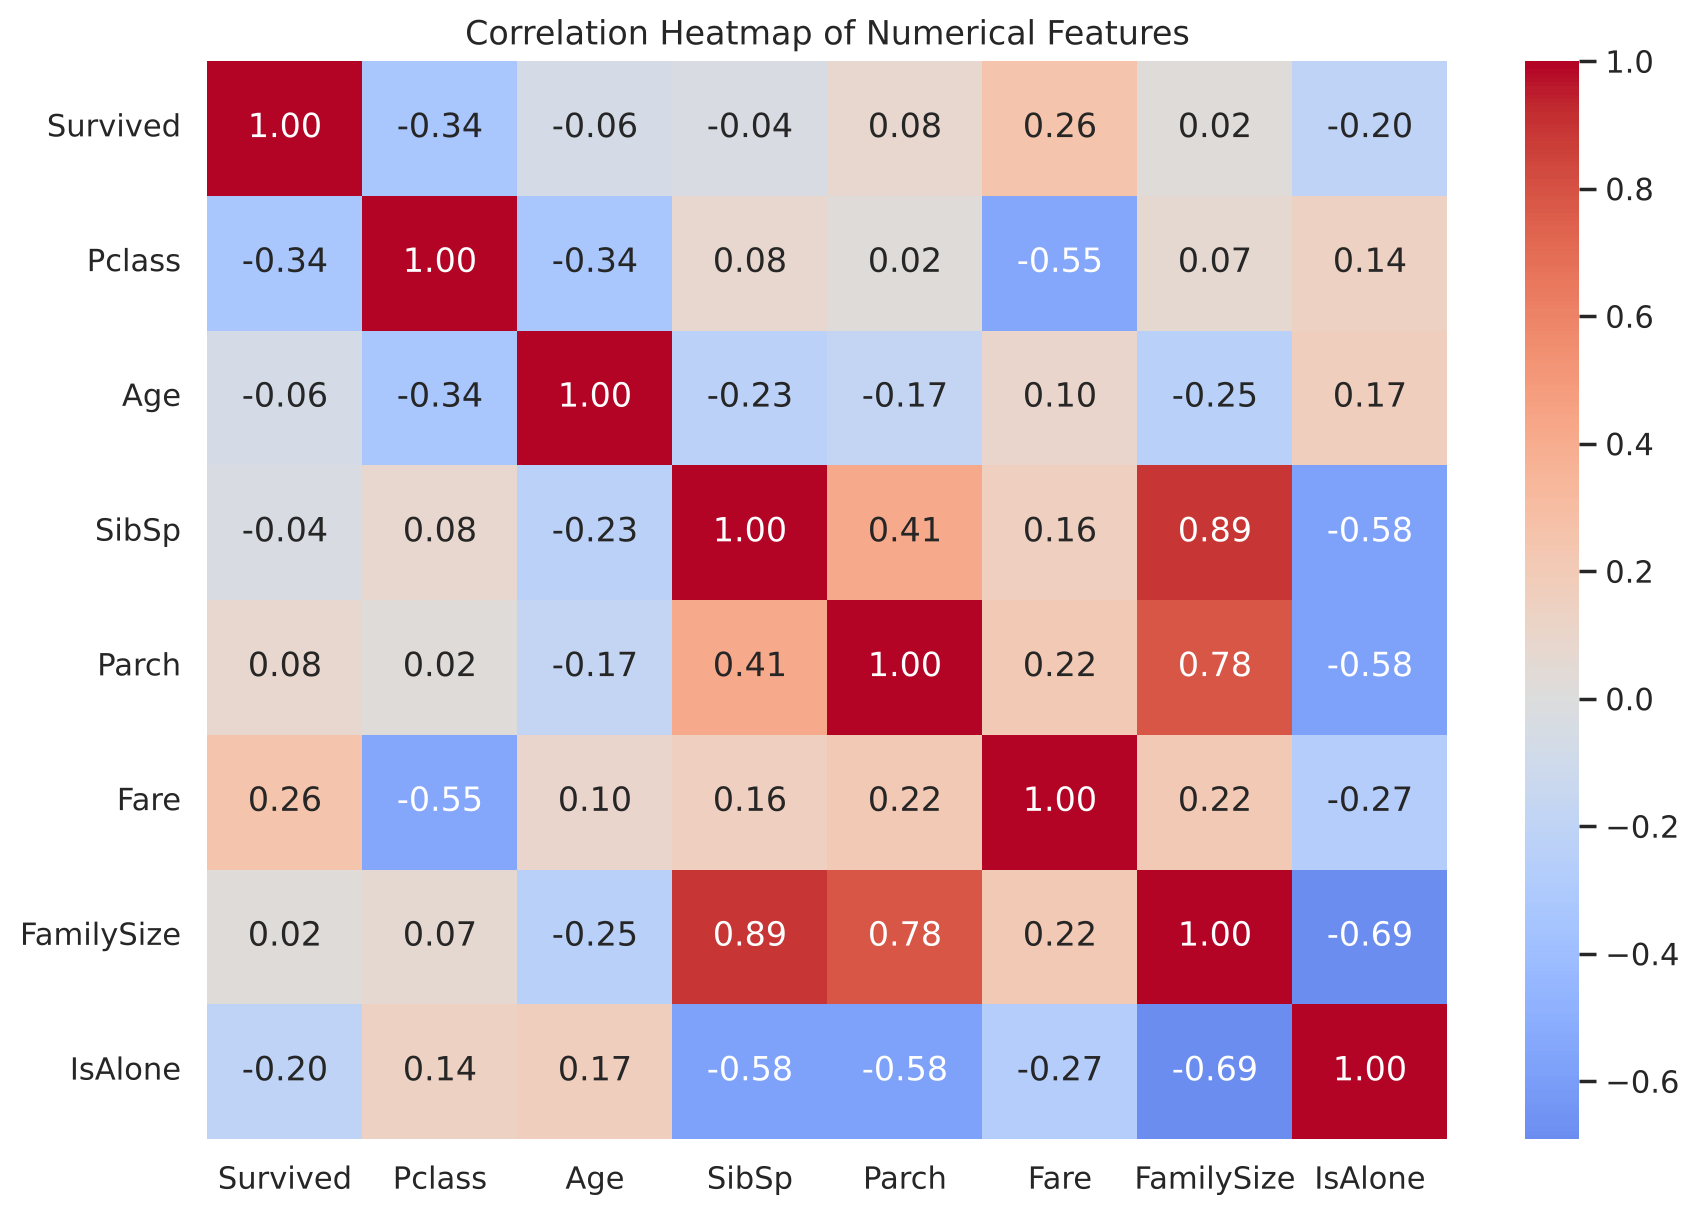

In [13]:
# Pclass is stored as a category, so select the numeric columns explicitly (PassengerId is just an ID, so it is excluded).
heat_cols = [c for c in ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone"] if c in df_clean.columns]
numeric_df = df_clean[heat_cols].astype(float)
correlation_matrix = numeric_df.corr()

display(correlation_matrix.round(2))

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()


## 14. Key findings (generated from the data)

In [14]:
overall_survival_rate = df_clean["Survived"].mean() * 100
print(f"Overall survival rate: {overall_survival_rate:.1f}%")

if not gender_survival.empty:
    best_gender = gender_survival.loc[gender_survival["Survival_Rate"].idxmax()]
    print(
        f"Highest survival rate by gender: {best_gender['Sex']} "
        f"({best_gender['Survival_Rate']:.1f}%)."
    )

if not class_survival.empty:
    best_class = class_survival.loc[class_survival["Survival_Rate"].idxmax()]
    print(
        f"Highest survival rate by passenger class: "
        f"Class {int(best_class['Pclass'])} ({best_class['Survival_Rate']:.1f}%)."
    )

if "Embarked" in df_clean.columns and "embarked_survival" in globals() and not embarked_survival.empty:
    best_port = embarked_survival.loc[embarked_survival["Survival_Rate"].idxmax()]
    print(
        f"Highest survival rate by embarkation port: "
        f"{best_port['Embarked']} ({best_port['Survival_Rate']:.1f}%)."
    )

print("\nInterpretation reminder:")
print("- These are descriptive patterns, not proof that one feature caused survival.")
print("- Group sizes should be considered when comparing percentages.")
print("- Correlation does not imply causation.")


Overall survival rate: 38.4%
Highest survival rate by gender: female (74.2%).
Highest survival rate by passenger class: Class 1 (63.0%).
Highest survival rate by embarkation port: C (55.4%).

Interpretation reminder:
- These are descriptive patterns, not proof that one feature caused survival.
- Group sizes should be considered when comparing percentages.
- Correlation does not imply causation.


## 15. Final conclusion

*(Draft based on the results above. Edit it in your own words.)*

- **Overall:** 38.4% of the 891 passengers survived.
- **Gender:** women survived at 74.2% versus 18.9% for men, the strongest pattern in the data.
- **Class:** survival fell with class: 63.0% (1st), 47.3% (2nd), 24.2% (3rd).
- **Gender x class:** almost all 1st and 2nd class women survived (96.8% and 92.1%), while 3rd class women survived at 50.0% and 3rd class men at only 13.5%.
- **Age:** children (12 and under) had the highest survival at 58.0%, and seniors the lowest at 22.7% (only 22 passengers).
- **Family size:** passengers with 2 to 4 family members aboard survived more (55% to 72%) than those travelling alone (30.4%) or in very large families (5 or more).
- **Port:** Cherbourg had the highest survival (55.4%), probably because it had more 1st class passengers (a class effect, not a port effect).
- **Correlations:** `Survived` is correlated with `Fare` (+0.26) and `Pclass` (-0.34), and `Pclass` and `Fare` are strongly negatively correlated (-0.55).
- **Limitation:** Age was imputed with the median (about 20% of ages were missing), and the analysis is observational, so it does not prove causation.

### Elevvo Task 2 checklist
- [x] Load Titanic dataset using Python.
- [x] Inspect data and generate summary statistics.
- [x] Check and handle missing values.
- [x] Check and remove duplicate rows.
- [x] Check/convert relevant data types.
- [x] Analyze survival by gender and passenger class.
- [x] Visualize key patterns and correlations.
- [x] Add bar plots and a correlation heatmap (bonus).
